Source: https://www.kaggle.com/code/lukhilaksh/diabetes-risk-80-beats

NOTEBOOK NOT CREATED BY ME

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename)) 

In [7]:
import kagglehub
from pathlib import Path

file_path = "/data"

path = kagglehub.dataset_download(
  "mansiaggarwal88/diabetes-risk-prediction",
  output_dir=file_path
)

csv_files = list(Path(file_path).glob("*.csv"))
df = pd.read_csv(csv_files[0])

df.head()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [9]:
df.shape

(15000, 19)

In [10]:
df.columns

Index(['patient_id', 'age', 'gender', 'city', 'bmi', 'family_history_diabetes',
       'physical_activity_level', 'diet_type', 'smoking_status',
       'alcohol_consumption', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm', 'income_bracket',
       'diabetes_risk'],
      dtype='str')

In [11]:
df.dtypes

patient_id                    int64
age                           int64
gender                          str
city                            str
bmi                         float64
family_history_diabetes         str
physical_activity_level         str
diet_type                       str
smoking_status                  str
alcohol_consumption             str
hours_sleep_per_night       float64
stress_level                  int64
fasting_blood_sugar           int64
hba1c_level                 float64
blood_pressure_systolic       int64
blood_pressure_diastolic      int64
waist_circumference_cm      float64
income_bracket                  str
diabetes_risk                   str
dtype: object

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  str    
 3   city                      15000 non-null  str    
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  str    
 6   physical_activity_level   15000 non-null  str    
 7   diet_type                 15000 non-null  str    
 8   smoking_status            14528 non-null  str    
 9   alcohol_consumption       11212 non-null  str    
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  float64
 14  blood_pressure_sy

In [14]:
df.isnull().sum()

patient_id                     0
age                            0
gender                         0
city                           0
bmi                            0
family_history_diabetes        0
physical_activity_level        0
diet_type                      0
smoking_status               472
alcohol_consumption         3788
hours_sleep_per_night          0
stress_level                   0
fasting_blood_sugar            0
hba1c_level                    0
blood_pressure_systolic        0
blood_pressure_diastolic       0
waist_circumference_cm         0
income_bracket               463
diabetes_risk                  0
dtype: int64

In [17]:
df.drop(columns=['smoking_status', 'alcohol_consumption', 'income_bracket'], inplace=True)

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.describe()

,patient_id,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,4330.271354,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,1.000000,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,3750.750000,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,7500.500000,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,11250.250000,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,15000.000000,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


# EDA

In [20]:
def show_fig():
    plt.tight_layout()
    plt.show()
    
plot_no = 1

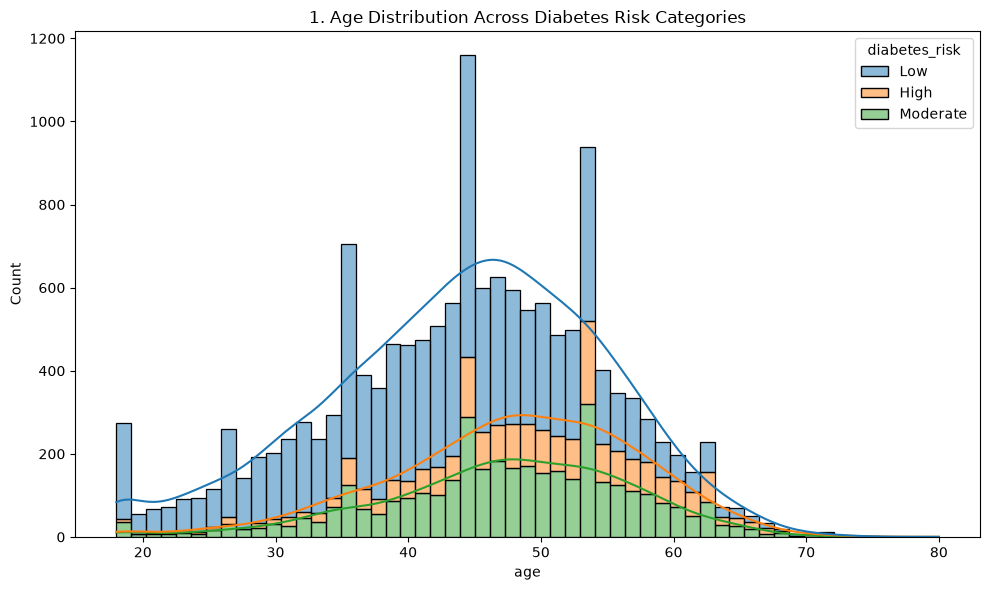

In [21]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='age', hue='diabetes_risk', kde=True, multiple='stack')
plt.title(f'{plot_no}. Age Distribution Across Diabetes Risk Categories')
show_fig()
plot_no += 1


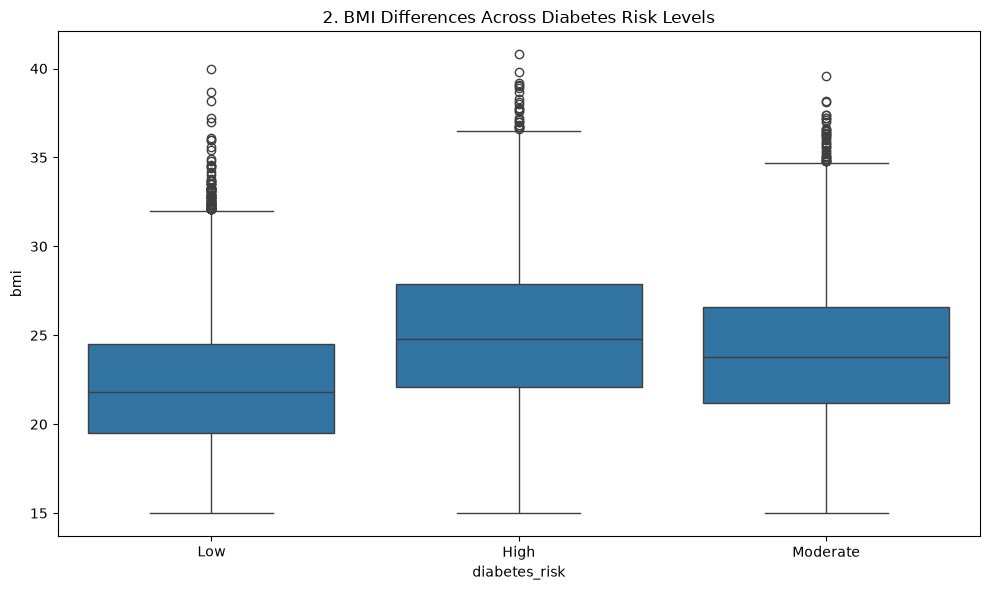

In [22]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='diabetes_risk', y='bmi')
plt.title(f'{plot_no}. BMI Differences Across Diabetes Risk Levels') 
show_fig()
plot_no += 1

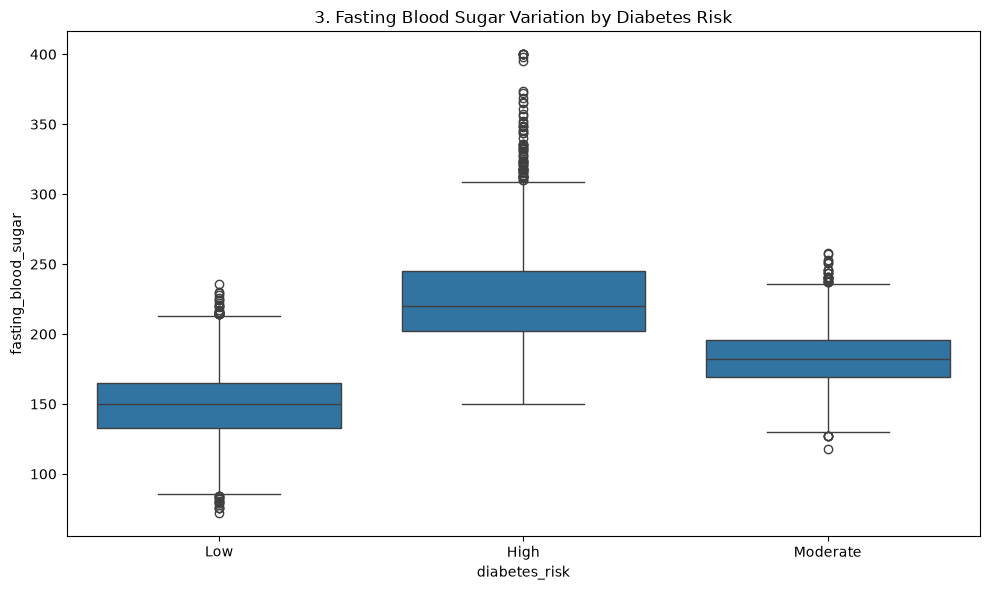

In [24]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='diabetes_risk', y='fasting_blood_sugar')
plt.title(f'{plot_no}. Fasting Blood Sugar Variation by Diabetes Risk')
show_fig()
plot_no += 1

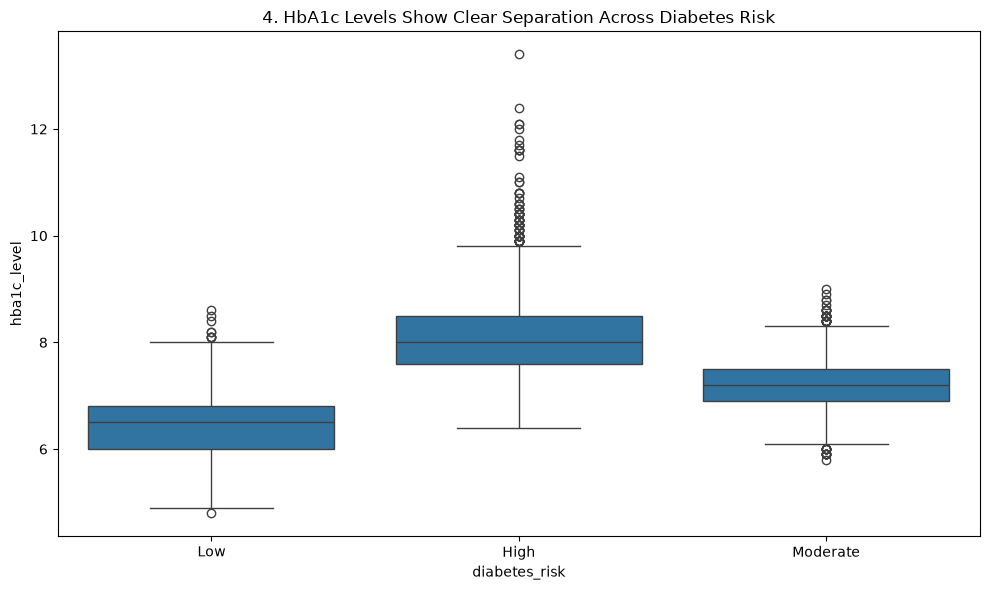

In [25]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='diabetes_risk', y='hba1c_level')
plt.title(f'{plot_no}. HbA1c Levels Show Clear Separation Across Diabetes Risk')
show_fig()
plot_no += 1

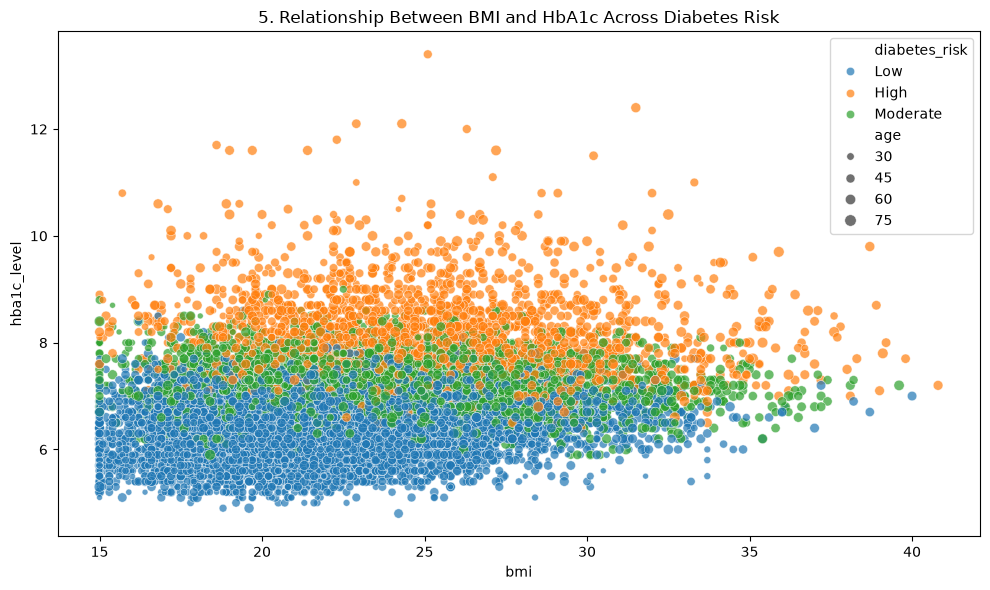

In [26]:
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='bmi', y='hba1c_level', hue='diabetes_risk', size='age', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between BMI and HbA1c Across Diabetes Risk')
show_fig()
plot_no += 1

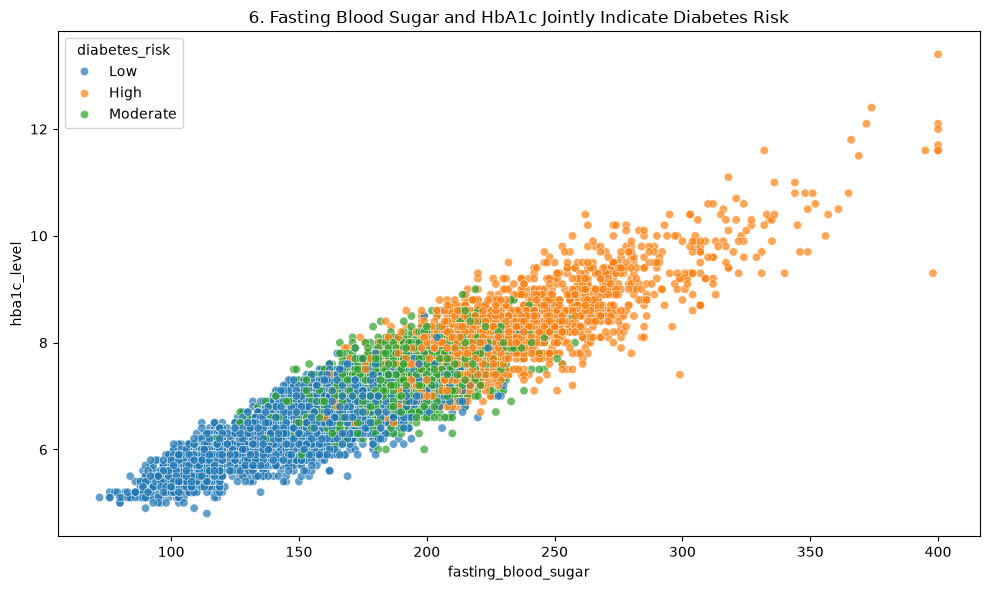

In [28]:
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='fasting_blood_sugar', y='hba1c_level', hue='diabetes_risk', alpha=0.7)
plt.title(f'{plot_no}. Fasting Blood Sugar and HbA1c Jointly Indicate Diabetes Risk')
show_fig()
plot_no += 1

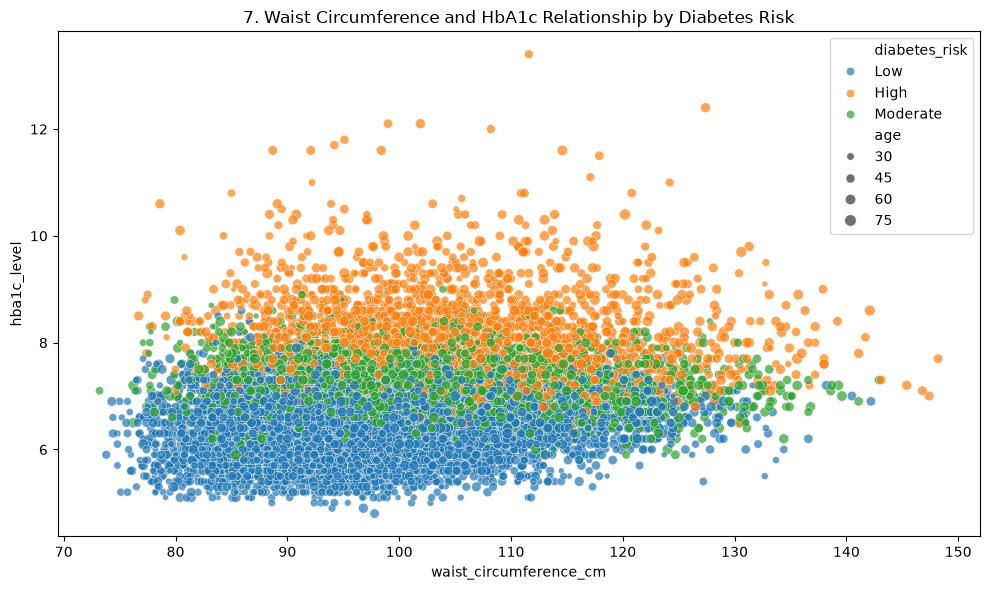

In [29]:
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='waist_circumference_cm', y='hba1c_level', hue='diabetes_risk', size='age', alpha=0.7)
plt.title(f'{plot_no}. Waist Circumference and HbA1c Relationship by Diabetes Risk')
show_fig()
plot_no += 1

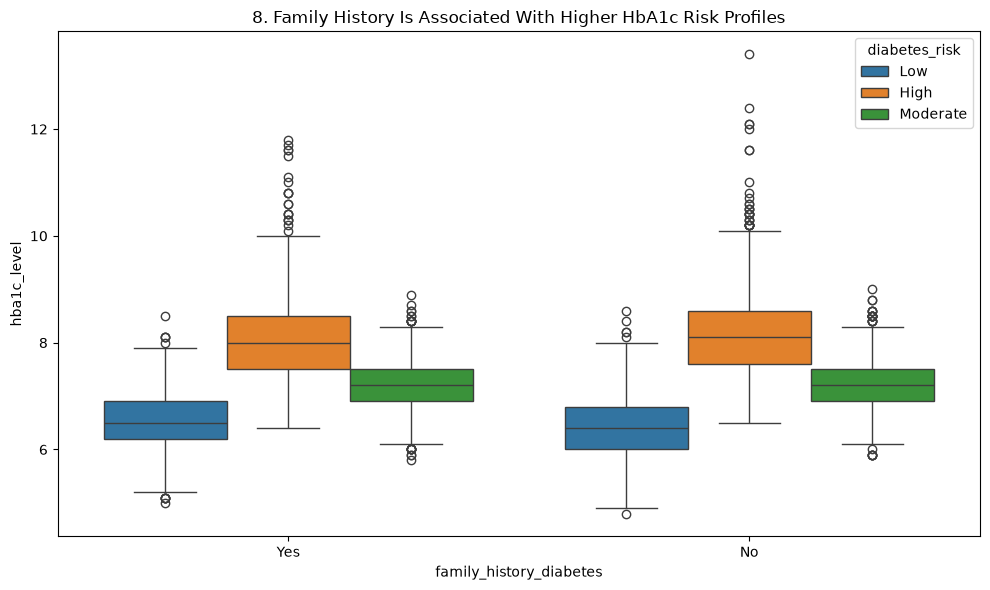

In [30]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='family_history_diabetes', y='hba1c_level', hue='diabetes_risk')
plt.title(f'{plot_no}. Family History Is Associated With Higher HbA1c Risk Profiles')
show_fig()
plot_no += 1

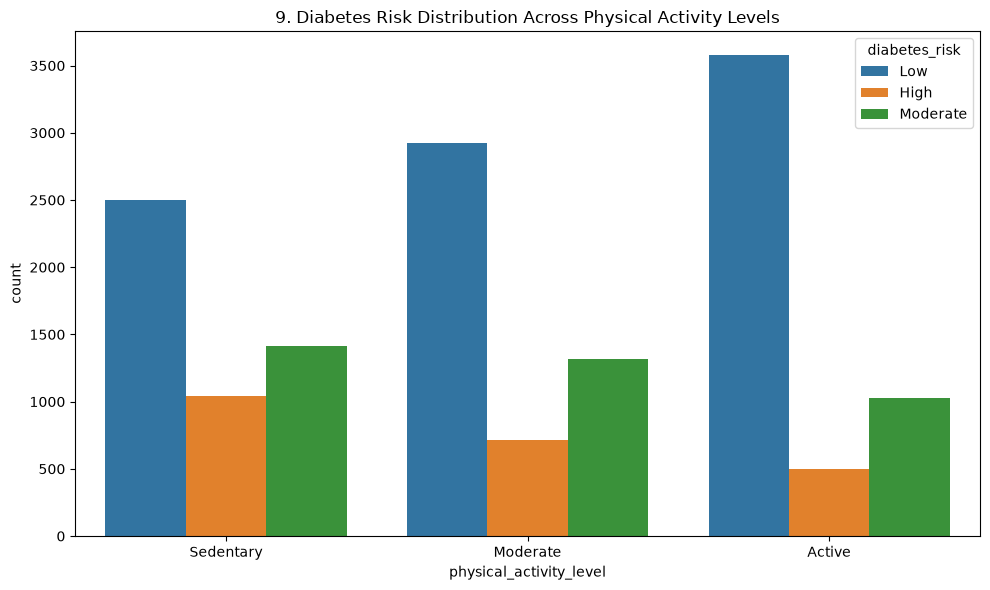

In [32]:
fig = plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='physical_activity_level', hue='diabetes_risk')
plt.title(f'{plot_no}. Diabetes Risk Distribution Across Physical Activity Levels')
show_fig()
plot_no += 1

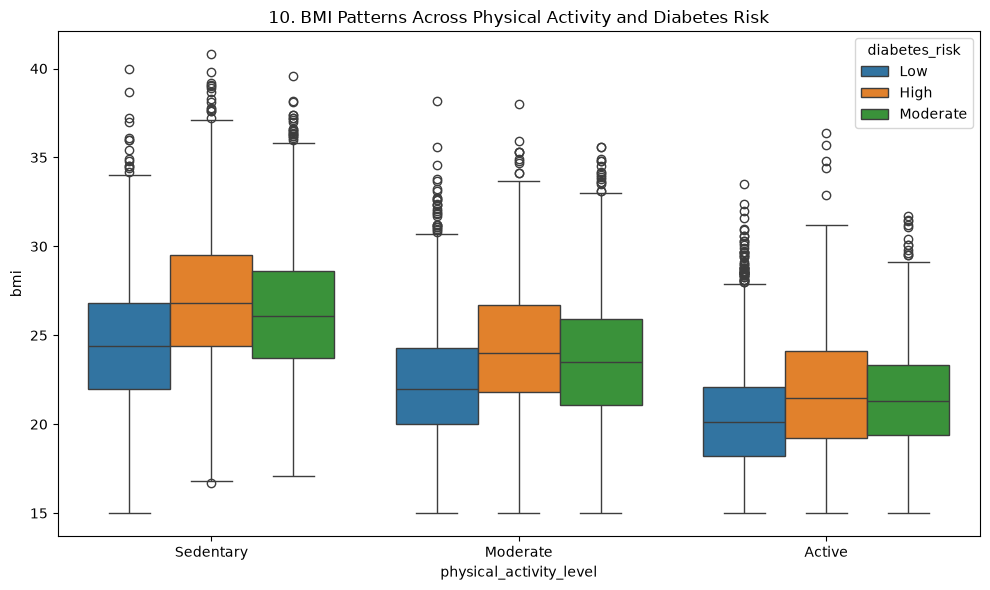

In [34]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='physical_activity_level', y='bmi', hue='diabetes_risk')
plt.title(f'{plot_no}. BMI Patterns Across Physical Activity and Diabetes Risk')
show_fig()
plot_no += 1

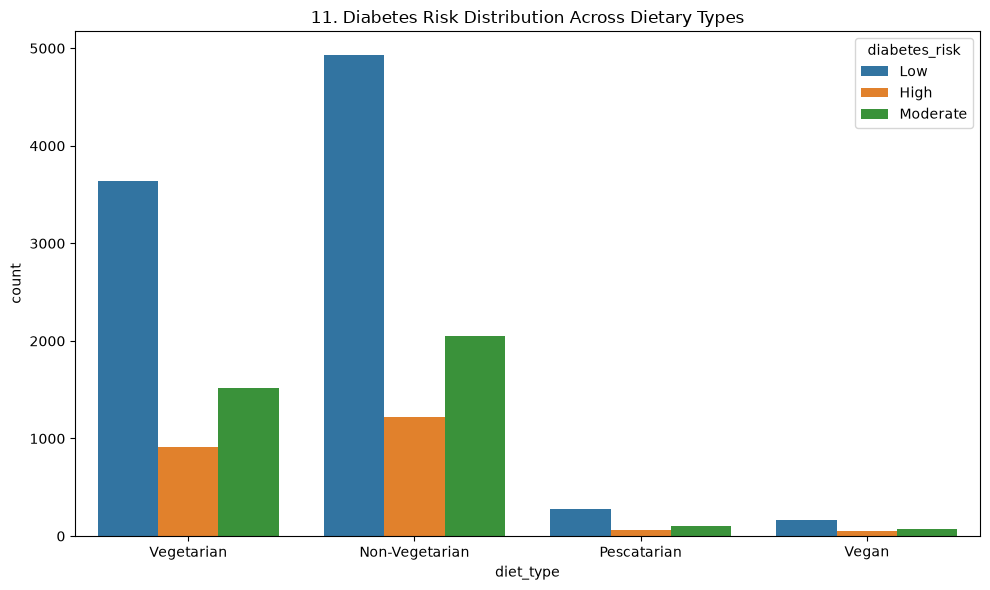

In [35]:
fig = plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='diet_type', hue='diabetes_risk')
plt.title(f'{plot_no}. Diabetes Risk Distribution Across Dietary Types')
show_fig()
plot_no += 1

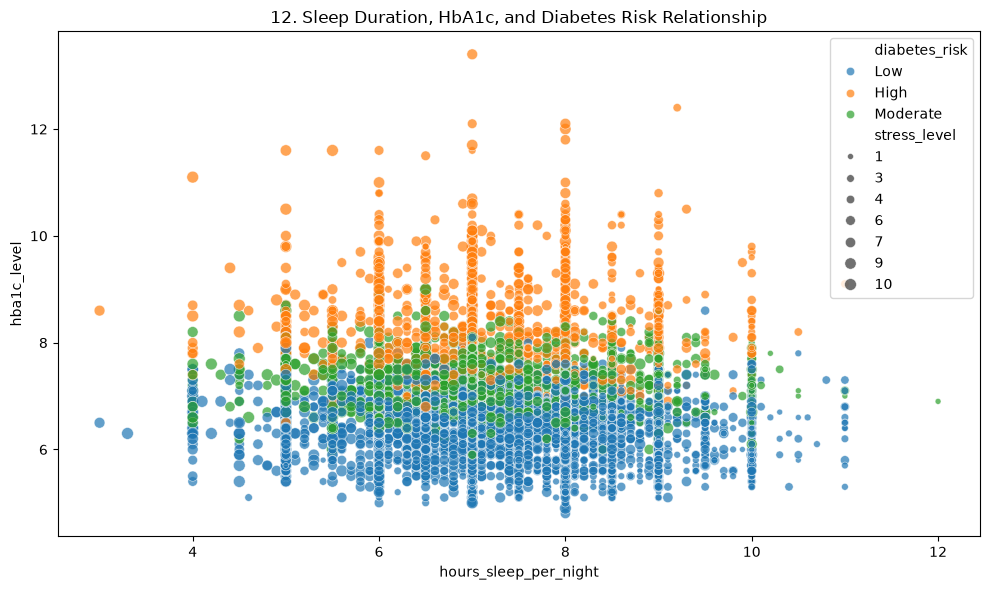

In [38]:
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='hours_sleep_per_night', y='hba1c_level', hue='diabetes_risk', size='stress_level', alpha=0.7)
plt.title(f'{plot_no}. Sleep Duration, HbA1c, and Diabetes Risk Relationship')
show_fig()
plot_no += 1

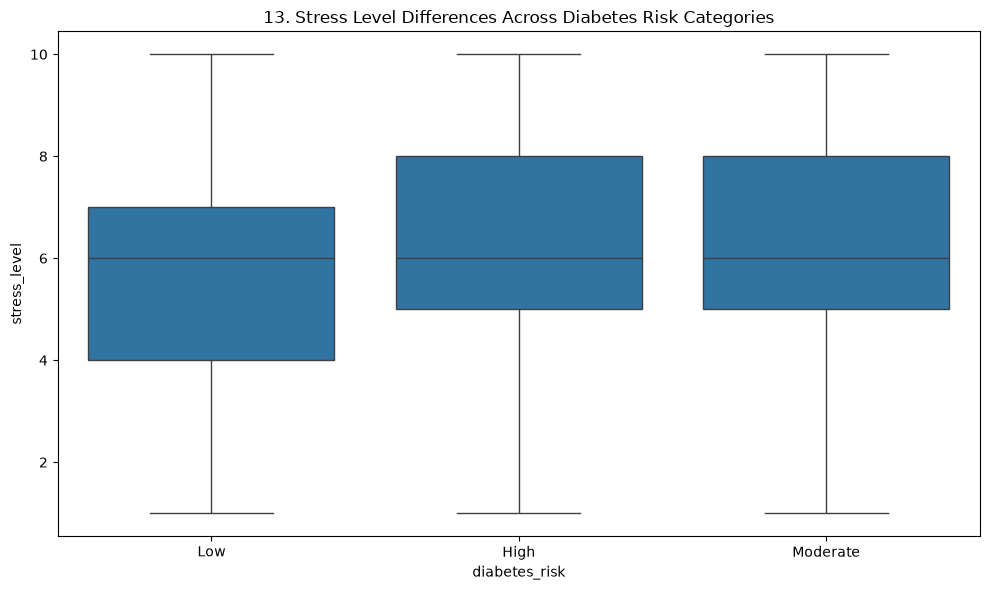

In [39]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='diabetes_risk', y='stress_level')
plt.title(f'{plot_no}. Stress Level Differences Across Diabetes Risk Categories')
show_fig()
plot_no += 1

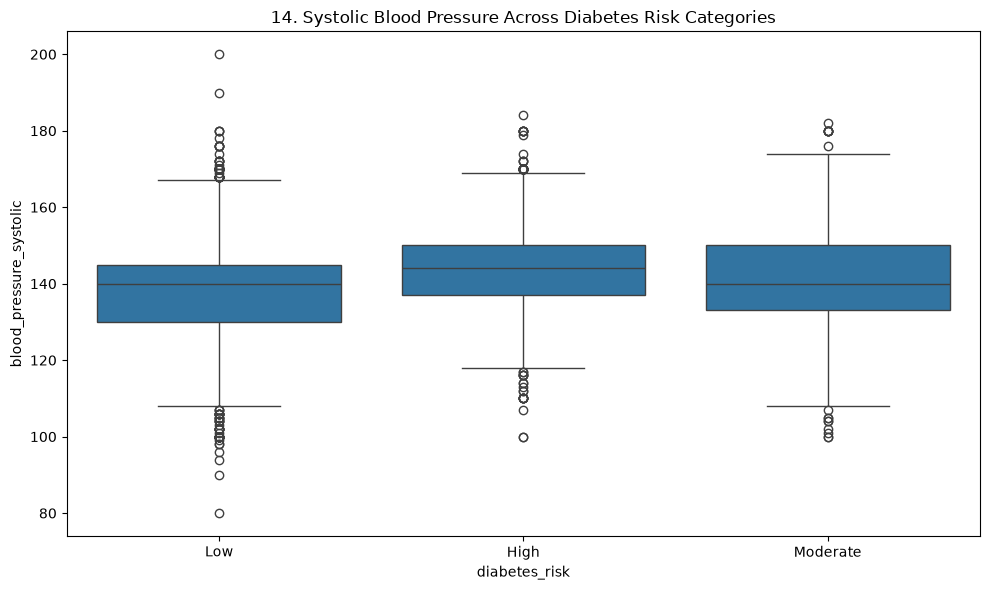

In [40]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='diabetes_risk', y='blood_pressure_systolic')
plt.title(f'{plot_no}. Systolic Blood Pressure Across Diabetes Risk Categories')
show_fig()
plot_no += 1

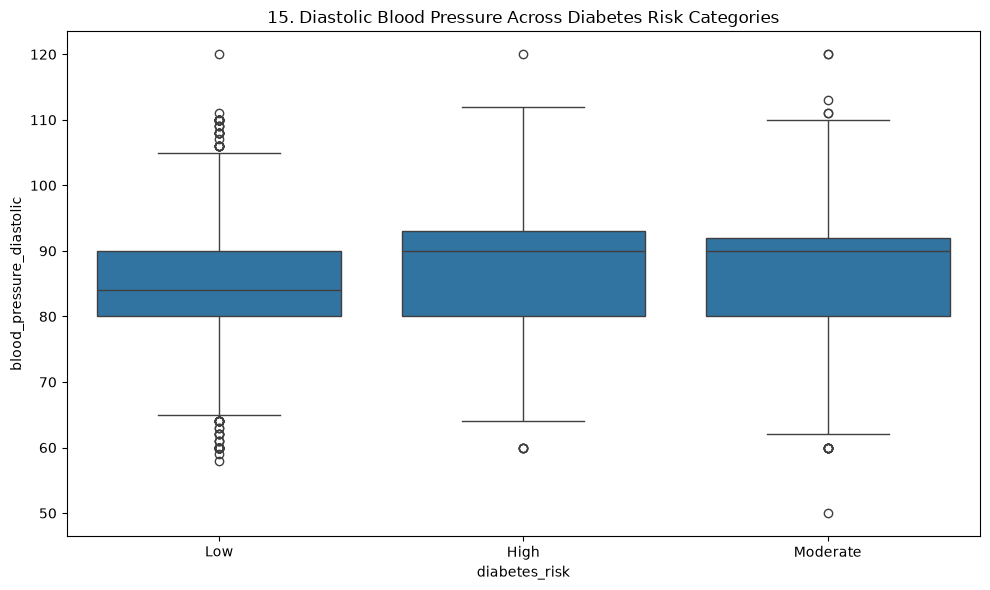

In [41]:
fig = plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='diabetes_risk', y='blood_pressure_diastolic')
plt.title(f'{plot_no}. Diastolic Blood Pressure Across Diabetes Risk Categories')
show_fig()
plot_no += 1

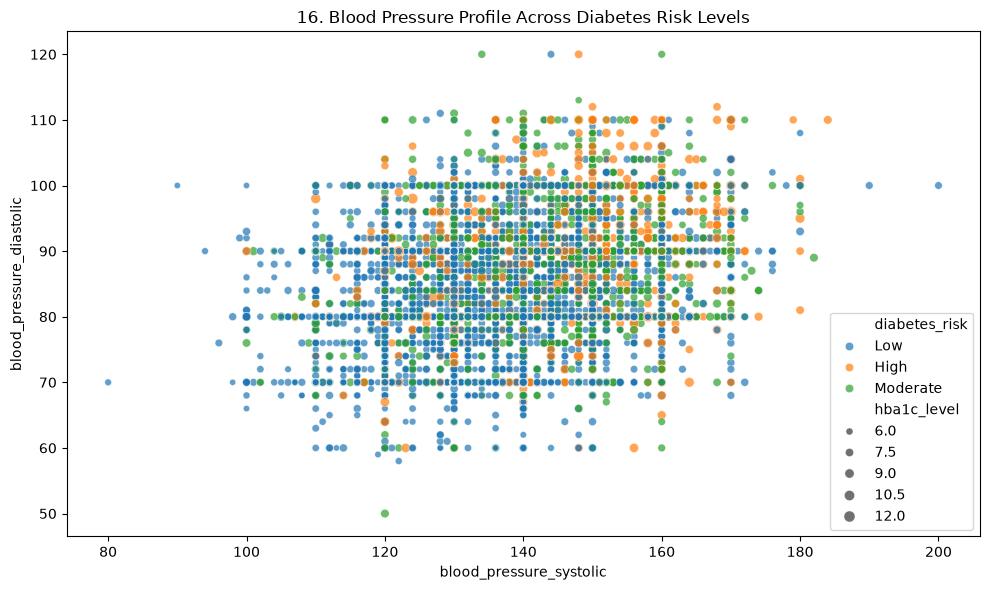

In [44]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='blood_pressure_systolic', y='blood_pressure_diastolic', hue='diabetes_risk', size='hba1c_level', alpha=0.7)
plt.title(f'{plot_no}. Blood Pressure Profile Across Diabetes Risk Levels')
show_fig()
plot_no += 1

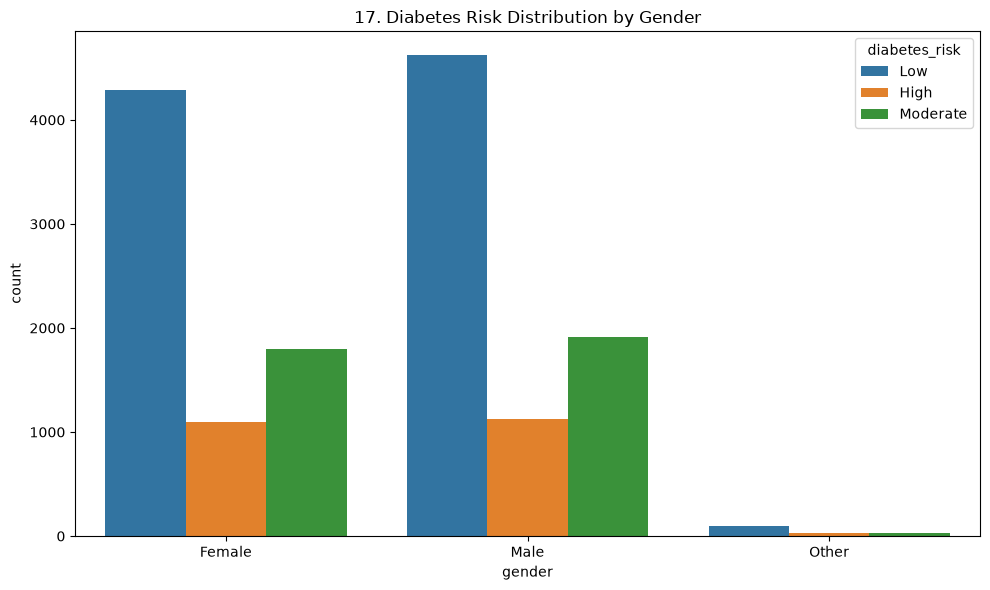

In [45]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='gender', hue='diabetes_risk')
plt.title(f'{plot_no}. Diabetes Risk Distribution by Gender')
show_fig()
plot_no += 1

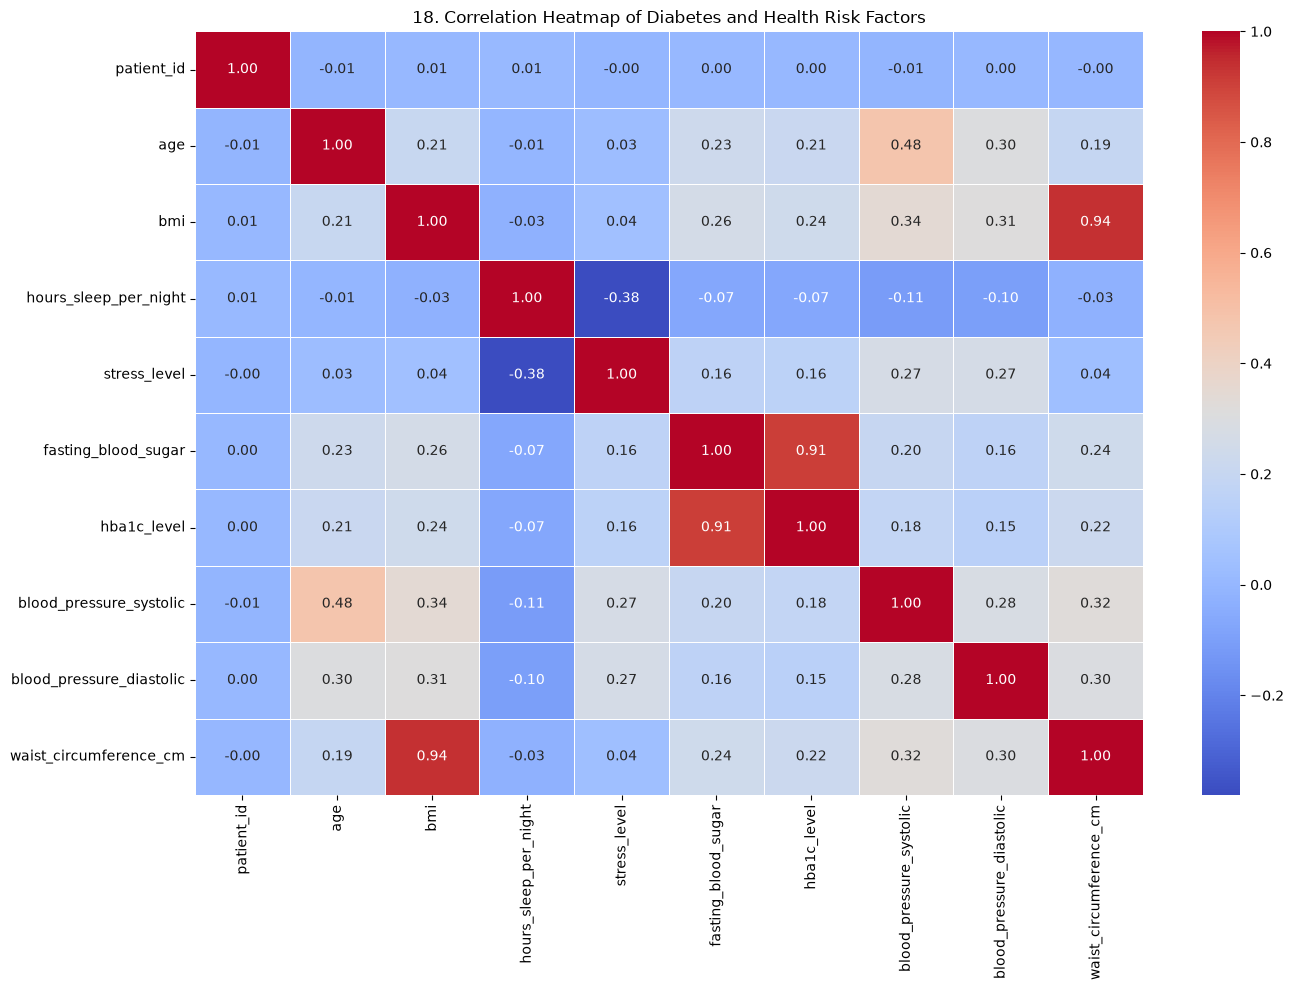

In [46]:
corr = df.select_dtypes(include='number').corr()

fig = plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Diabetes and Health Risk Factors')
show_fig()
plot_no += 1

In [48]:
X = df.drop(columns=['patient_id', 'diabetes_risk'])
y = df['diabetes_risk']

In [49]:
X = pd.get_dummies(X, drop_first=True)

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [51]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [52]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [53]:
y_pred = model.predict(X_test)

In [54]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy}")
print(f"Model Accuracy (%): {accuracy * 100}")

Model Accuracy: 0.7956666666666666
Model Accuracy (%): 79.56666666666666
